# M07-2 | The Same Q/DQ Graph: What Each of Three Treatments Turns It Into

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m07_representation_lowering/02_representation_and_lowering.ipynb)

Up to M06, the result of `convert_pt2e` has always been a Q/DQ graph: the operations are still fp32 (conv2d, linear, ...), wrapped in quantize / dequantize, and it does not get faster by itself (M02-3).
To turn it into integer arithmetic, something has to "rewrite" the graph. This notebook takes one Q/DQ graph and looks at what each of three treatments does. The definitions of the three terms and how they relate are in the [M07 overview](00_overview.ipynb).

- **A.** The starting point: the "dq → op → q" units on the Q/DQ graph, which are exactly what a backend must recognize and replace with int8 kernels.
- **B.** Reference representation: `convert_pt2e(..., use_reference_representation=True)`.
- **C.** Lowering: `lower_pt2e_quantized_to_x86`.
- **D.** Inductor: what `torch.compile` does to a Q/DQ graph (using the profiler to see the kernels actually run).

At the end, one summary table compares what the conv unit becomes under the three treatments.

In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import the course's common/
    os.chdir(f"{repo}/en/m07_representation_lowering")

In [2]:
import copy
from collections import Counter

import torch

from common.data import calibration_batches, trained_tiny_net
from common.env import cpu_profile, env_summary
from common.graph_utils import QDQ_PREFIXES, diff_ops, op_counts, qdq_nodes, short
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, lower_pt2e_quantized_to_x86, prepare_pt2e, quiet
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed

**The results depend on the platform**: A and B are pure graph rewrites and only change with the torch / torchao versions; C and D depend on the machine (whether mkldnn is available, which kernel conv uses).
The outputs stored below were produced in this environment; the notes under the tables are printed according to the measured results:

In [3]:
print(env_summary())

Linux x86_64 | torch 2.14.0+cu130 | threads=1 | mkldnn=True | nnpack=True


The model is M05's `TinyConvNet`, quantized with PTQ using XNNPACKQuantizer (per-channel weight) to get the Q/DQ graph:

In [4]:
def calibrated(model, per_channel=True):
    """export → prepare (XNNPACKQuantizer) → calibrate; returns the prepared graph, not yet converted."""
    prepared = prepare_pt2e(export_module(model, example_inputs()), get_xnnpack_quantizer(is_per_channel=per_channel)[0])
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return prepared


model = trained_tiny_net()
qdq = convert_pt2e(calibrated(model))
(x,) = next(calibration_batches(16, seed=9))

## A. The starting point: "dq → op → q" units on the Q/DQ graph

Walk back from each activation's quantize until reaching a dequantize; the ops passed through in between form one unit.
The `qdq_units` below only recognizes the per-tensor activation q/dq produced by XNNPACKQuantizer; it is not a general pattern detector:

In [5]:
def qdq_units(gm):
    """Return {unit op: (count, whether the input and output (scale, zp) are all the same)}."""
    units, same = Counter(), {}
    for q in gm.graph.nodes:
        if q.target != QD.quantize_per_tensor.default:
            continue
        ops, in_qparams, frontier = [], set(), [q.args[0]]
        while frontier:
            n = frontier.pop()
            if n.target == QD.dequantize_per_tensor.default:
                in_qparams.add(tuple(n.args[1:3]))  # the input (scale, zp)
            if n.op != "call_function" or str(n.target).startswith(QDQ_PREFIXES):
                continue  # stop at dequantize / quantize / placeholder / get_attr
            ops.append(short(n.target))
            frontier += n.all_input_nodes
        if ops:
            key = " + ".join(reversed(ops))
            units[key] += 1
            same[key] = same.get(key, True) and in_qparams == {tuple(q.args[1:3])}
    return {k: (v, same[k]) for k, v in units.items()}


units = dict(sorted(qdq_units(qdq).items(), key=lambda kv: -kv[1][0]))
table([[k, n, "yes" if s else "no"] for k, (n, s) in units.items()], ["ops in dq → [op] → q", "count", "same qparams in/out?"])

ops in dq → [op] → q,count,same qparams in/out?
conv2d + relu,3,no
max_pool2d,2,yes
conv2d,1,no
add + relu,1,no
adaptive_avg_pool2d,1,yes
flatten,1,yes
linear,1,no


In [6]:
assert units["conv2d + relu"][0] >= 1 and not units["conv2d + relu"][1]
assert units["max_pool2d"][1]  # max_pool2d shares qparams between input and output (M03-4)

Take the `add + relu` unit of a residual block as an example: two dequantizes go in and one quantize comes out, and the add and relu in between are fp32:

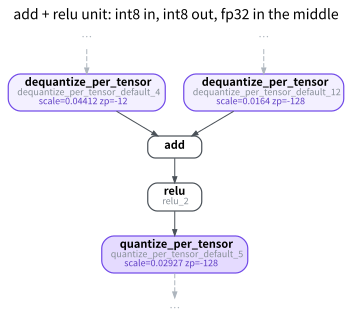

In [7]:
draw(qdq, focus=["add", "relu_2"], hops=1, title="add + relu unit: int8 in, int8 out, fp32 in the middle")

- Every unit has the same semantics: "int8 in, int8 out, computed in fp32 in the middle". What a backend does is recognize these units and replace them with its own int8 kernels (for example, conv2d + relu becomes one int8 conv-relu).
- The Q/DQ graph is not tied to any backend: the same graph can be handed to Inductor (C and D of this notebook), XNNPACK (M08), or ONNX Runtime (M09), each recognizing it with its own patterns. This is what "Q/DQ is a backend-neutral interchange format" means.
- **Units whose input and output share qparams** (the ones marked "yes" in the table above, the Shared case of M03-4): an integer kernel does not need to change scale, and max / flatten just move int8 values.
- **Units whose output scale differs from the input**: the integer kernel has to requantize at the end, converting the accumulated result to the output scale.

## B. Reference representation

`convert_pt2e(..., use_reference_representation=True)` writes Q/DQ as visible arithmetic, and rewrites the units that match a torchao pattern into integer arithmetic.
Start with the smallest conv_relu. The two graphs below show the segment before conv's input x enters conv2d, with the constant parameters (scale, zp, dtype) under each node:

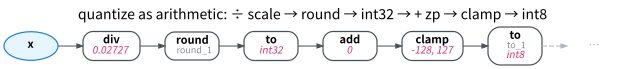

In [8]:
small = convert_pt2e(calibrated(get_model("conv_relu").eval()), use_reference_representation=True)


def literal(node):
    args = [a for a in node.args[1:] if not hasattr(a, "op")]
    if args:
        return ", ".join(f"{a:.4g}" if isinstance(a, float) else str(a).replace("torch.", "") for a in args)
    return str(node.kwargs.get("dtype", "")).replace("torch.", "")


chain, n = [], next(n for n in small.graph.nodes if n.name == "conv2d").args[0]
while n.op == "call_function":
    chain.append(n)
    n = n.args[0]
chain.reverse()  # from the first op after x up to just before conv2d
split = next(i for i, c in enumerate(chain) if torch.int8 in c.args) + 1  # everything up to the cast to int8 (to(int8)) is quantize
quant_part, dequant_part = chain[:split], chain[split:]
notes = {c.name: literal(c) for c in chain}
draw(small, focus=["x"] + [c.name for c in quant_part], hops=0, notes=notes, rankdir="LR",
     title="quantize as arithmetic: ÷ scale → round → int32 → + zp → clamp → int8")

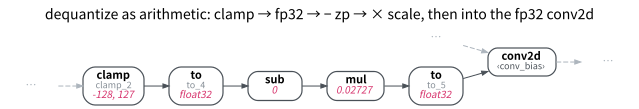

In [9]:
draw(small, focus=[c.name for c in dequant_part] + ["conv2d"], hops=0, notes=notes, rankdir="LR",
     title="dequantize as arithmetic: clamp → fp32 → − zp → × scale, then into the fp32 conv2d")

In [10]:
assert [short(c.target) for c in quant_part][:2] == ["div", "round"] and short(dequant_part[-2].target) == "mul"

Both quantize and dequantize become ordinary ATen arithmetic, in which `÷ scale`, `round`, and `× scale` are still floating-point operations: this step is "writing the formula out", not switching to an int8 kernel. conv2d itself is unchanged.

Now switch to `TinyConvNet` and compare the per-channel and per-tensor weight settings. torchao wraps the ops rewritten to int32 arithmetic in `out_dtype`, so counting those tells which units were rewritten:

In [11]:
def integer_ops(gm):
    """Ops wrapped by out_dtype (computed in int32); the first argument of out_dtype is the wrapped op."""
    return Counter(short(n.args[0]) for n in gm.graph.nodes if short(n.target) == "out_dtype")


b = {}
for label, per_channel in (("per-channel weight (default)", True), ("per-tensor weight", False)):
    ref = convert_pt2e(calibrated(model, per_channel), use_reference_representation=True)
    c = op_counts(ref)
    b[label] = (sum(v for k, v in c.items() if k.startswith(("quantize", "dequantize"))), c["conv2d"], c["linear"],
                integer_ops(ref))
table([[k, q, cv, ln, ", ".join(f"{op}×{m}" for op, m in ints.items()) or "—"] for k, (q, cv, ln, ints) in b.items()],
      ["TinyConvNet", "remaining q/dq", "fp32 conv2d", "fp32 linear", "ops computed in int32 (out_dtype)"])

TinyConvNet,remaining q/dq,fp32 conv2d,fp32 linear,ops computed in int32 (out_dtype)
per-channel weight (default),0,4,1,mul×2
per-tensor weight,0,4,0,"mul×3, linear×1, div×1"


In [12]:
q_left, n_conv, _, _ = b["per-channel weight (default)"]
assert q_left == 0 and n_conv == 4  # torchao 0.18: q/dq all become arithmetic, conv is not rewritten
assert b["per-tensor weight"][2] == 0 and b["per-tensor weight"][3]["linear"] == 1  # per-tensor linear becomes integer

- q/dq all become arithmetic, with none left.
- **conv2d is still there**, consuming the fp32 produced by dequantize: the conv unit was not rewritten into integer arithmetic. The reason (from reading torchao 0.18's `reference_representation_rewrite.py`): the conv pattern is written with `aten.convolution`, while `torch.export` produces `aten.conv2d`, so they do not match; the pattern is only written for per-tensor weight, and the conv output must feed directly into quantize (no relu in between). For what the whole unit becomes when all three conditions hold, see the [M07 overview](00_overview.ipynb), "Reference representation: writing Q/DQ as explicit arithmetic" (the part about whether the whole unit matches a pattern).
- **What is rewritten into integer arithmetic**: the two inputs of add + relu each use an int32 mul to move to the output scale; with per-tensor weight, linear uses int32 accumulation, the bias is quantized with div, and a final mul does the requantize. For how this integer arithmetic is derived from the affine quantization formula, see the section "Pure Integer Arithmetic" in the blog post "[All About Quantization](https://bobondemon.github.io/2020/10/03/Quantization-%E7%9A%84%E9%82%A3%E4%BA%9B%E4%BA%8B/#%E7%B4%94%E7%94%A8-Integer-%E9%81%8B%E7%AE%97)" (in Chinese).

So reference representation is a "partial" rewrite: q/dq always become arithmetic, and whether an operation becomes integer depends on whether a pattern matches.

## C. Lowering: `lower_pt2e_quantized_to_x86`

This function does three things: re-export and decompose (for example, conv2d → convolution), run Inductor's freezing pass, and constant folding.
The x86 int8 patterns (for example, dq → conv → q replaced by `onednn.qconv_pointwise`) are only registered when mkldnn is available (overview, "How the three relate"). The table below shows the op changes before and after lowering:

In [13]:
lowered = lower_pt2e_quantized_to_x86(copy.deepcopy(qdq), (x,))
table(diff_ops(qdq, lowered, "Q/DQ graph", "after lowering", tablefmt="html"))

op,Q/DQ graph,after lowering,delta
adaptive_avg_pool2d,1,0,-1
conv2d,4,0,-4
dequantize_per_channel,5,0,-5
dequantize_per_tensor,12,7,-5
flatten,1,0,-1
getitem,0,2,2
linear,1,0,-1
max_pool2d,2,0,-2
max_pool2d_with_indices,0,2,2
mean,0,1,1


In [14]:
onednn = Counter(short(n.target) for n in lowered.graph.nodes if "onednn" in str(n.target))
n_before, n_after = len(qdq_nodes(qdq)), len(qdq_nodes(lowered))
mkldnn = torch.backends.mkldnn.is_available()
print(f"onednn ops: {dict(onednn) or 'none'}; q/dq: {n_before} → {n_after}; mkldnn available: {mkldnn}")
if onednn:
    print(f"The patterns matched: q/dq went from {n_before} to {n_after}, and these units were replaced with oneDNN int8 ops.")
elif not mkldnn:
    print("No mkldnn: the patterns are not registered, so the result is just a decomposed Q/DQ graph, with no q/dq removed.")
else:
    print("mkldnn is available but there are no onednn ops: the patterns are registered but did not match; see the op-change table above (not investigated here).")
if not mkldnn:
    assert not onednn and n_after == n_before

onednn ops: {'qconv_pointwise.default': 4, 'qlinear_pointwise.default': 1}; q/dq: 28 → 13; mkldnn available: True
The patterns matched: q/dq went from 28 to 13, and these units were replaced with oneDNN int8 ops.


Most of the changes in the table above are decompose (`conv2d` → `convolution`, `linear` → `addmm`, etc.). In an environment without mkldnn, this is the only step lowering has; which ops are actually present after lowering on x86 is not verified here.

## D. Inductor: what `torch.compile` does to a Q/DQ graph

The kernels generated by `torch.compile` do not show up under ATen op names in the profiler, so we compare two things: whether q/dq are still called as separate kernels, and which kernel conv actually runs.
The profiler uses `cpu_profile()` introduced in M07-1:

In [15]:
CONV_WRAPPERS = ("aten::conv2d", "aten::convolution", "aten::_convolution", "aten::_nnpack_available")
INT8_HINTS = ("qconv", "onednn::q", "quantized::")  # a name containing these is treated as an int8 conv (inference, based on the op names in x86.py)


def kernel_calls(fn, x):
    """Return (number of q/dq kernel calls, kernels conv actually runs, total op calls)."""
    with torch.no_grad():
        fn(x)  # run once first: compile happens here
        with cpu_profile() as prof:
            fn(x)
    names = [e.name for e in prof.events() or []]
    convs = sorted({s for s in names if "conv" in s and s not in CONV_WRAPPERS})
    return sum(s.startswith("quantized_decomposed::") for s in names), convs, sum("::" in s for s in names)


eager = kernel_calls(qdq, x)
try:
    compiled, compile_error = kernel_calls(torch.compile(copy.deepcopy(qdq)), x), None
except Exception as e:  # e.g. on x86 with mkldnn, Inductor rewrites max_pool2d into an op that fails at run time
    compiled, compile_error = None, f"{type(e).__name__}: {str(e).splitlines()[0][:150]}"
table([[name, n, ", ".join(k), total] for name, r in (("Q/DQ graph (eager)", eager), ("torch.compile(Q/DQ graph)", compiled)) if r for n, k, total in [r]],
      ["", "q/dq kernel calls", "kernel conv actually runs", "total op calls"])

,q/dq kernel calls,kernel conv actually runs,total op calls
Q/DQ graph (eager),28,aten::mkldnn_convolution,534


In [16]:
if compiled is None:
    is_int8 = False
    print(f"torch.compile failed on this machine, so there is nothing to compare: {compile_error}")
else:
    is_int8 = any(h in k for k in compiled[1] for h in INT8_HINTS)
    print(f"q/dq kernel calls: {eager[0]} → {compiled[0]}; op calls: {eager[2]} → {compiled[2]}")
    print("conv: " + ("int8 kernel" if is_int8 else "still fp32, no int8 conv"))
    assert compiled[0] < eager[0]

torch.compile failed on this machine, so there is nothing to compare: NotImplementedError: Could not run 'aten::quantized_max_pool2d' with arguments from the 'CPU' backend. This could be because the operator doesn't exist for this backend, o


- Inductor fuses the elementwise operations dequantize, relu, and quantize into the kernel it generates, so q/dq are no longer separate calls and the number of op calls drops sharply.
- Whether conv becomes int8 depends on the result printed above. Inductor's freezing setting is off by default (overview, "How the three relate"); the conv rewrite with the int8 patterns from section C only runs when it is on.
- Platform difference: on x86 with mkldnn (torch 2.14, Linux x86_64), Inductor's x86 quantization passes act whether or not freezing is on, and they fail: by default max_pool2d is rewritten into `aten::quantized_max_pool2d`, which has no CPU implementation (a `NotImplementedError` at run time); with freezing on, packing the weight of the quantized conv raises a dtype error. The outputs stored in the Chinese notebook come from macOS arm64, where the compile works (these x86 quantization passes do not apply to arm); the `try/except` above lets the notebook run to the end on x86 too.

## Summary table: what the conv unit becomes under the three treatments

In [17]:
rows = [
    ["reference representation", "became arithmetic" if q_left == 0 else f"{q_left} left",
     f"fp32 conv2d ({n_conv})" if n_conv else "integer conv", "no" if n_conv else "yes"],
    ["lower_pt2e_quantized_to_x86", "kept" if n_after == n_before else f"{n_before} → {n_after}",
     ", ".join(onednn) if onednn else "fp32 convolution", "yes" if onednn else "no"],
    ["torch.compile", "compile failed" if compiled is None else "fused into the generated kernel" if compiled[0] == 0 else "partly kept",
     "—" if compiled is None else ", ".join(compiled[1]) or "—",
     "yes" if is_int8 else "no"],
]
table(rows, ["treatment", "q/dq", "conv", "conv is integer arithmetic?"])

treatment,q/dq,conv,conv is integer arithmetic?
reference representation,became arithmetic,fp32 conv2d (4),no
lower_pt2e_quantized_to_x86,28 → 13,"qconv_pointwise.default, qlinear_pointwise.default",yes
torch.compile,compile failed,—,no


In [18]:
n_int = sum(r[3] == "yes" for r in rows)
print(f"{n_int} treatment(s) turned conv into integer arithmetic." if n_int else "None of the three treatments turned conv into an int8 kernel.")

1 treatment(s) turned conv into integer arithmetic.


The Q/DQ graph is only a spec of "where to quantize and with which qparams"; a real integer kernel needs the backend's patterns to recognize the units and replace them. x86 needs oneDNN; the path on arm is XNNPACK (M08).
How far the backend's real int8 kernel is from the Q/DQ graph numerically is measured in M08 and M09.

## Summary

- The Q/DQ graph is made of "dq → op → q" units and is a backend-neutral interchange format.
- Reference representation writes q/dq as arithmetic; an operation only becomes integer if it matches a torchao pattern (torchao 0.18's conv does not match).
- Lowering and `torch.compile` need the backend's int8 patterns to swap in kernels; without them, lowering is left with only decompose, and `torch.compile` only fuses elementwise operations (on x86 with mkldnn, Inductor's quantization passes can instead make the compile fail; see section D).